# 02b RQ2 exploratory: longshot bias by price band and format

**Exploratory (Section 8).** Nothing here is pre-registered, and none of it changes the
confirmatory RQ2 result in notebook 02.

**Why.** H2a is supported (1-day longshots overpriced by about 0.25¢), but the D8.5
descriptives put the whole effect in template markets: event longshots average about
0. Two readings need separating:

- **Tick floor.** Prices cannot go below the 0.1¢ tick. A near-impossible outcome
  priced at 0.1¢ is then "overpriced" mechanically, and template ladders hold many
  such strikes.
- **Real overpricing.** Template longshots are overpriced across the price range.

If the floor is the cause, the bias should sit in the 0.1¢ band and vanish above it.

**Method.** Same frame as H2a (primary population, 1 day, cheaper side below $0.10).
Per price band × format, and then × subject: the mean of (won − price) from an
intercept-only OLS with CR1 cluster SEs, as in D8.1, with 95% CIs and no p-values.
The bands are 0.1¢ (the floor tick), 0.2–0.5¢, 0.6–2¢, 2.1–5¢ and 5.1–10¢.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
LONGSHOT = 0.10
BANDS = [0, 0.0015, 0.0055, 0.0205, 0.0505, LONGSHOT]
LABELS = ["0.1c", "0.2-0.5c", "0.6-2c", "2.1-5c", "5.1-10c"]
pd.set_option("display.width", 200)

f = pd.read_parquet(DATA / "mart_analysis.parquet",
                    columns=["horizon", "snap_price", "is_primary", "format", "subject",
                             "cluster_id", "token1_won"])
d = f[f["is_primary"] & (f["horizon"] == "1d")].copy()
p = np.round(d["snap_price"], 6)
t1 = p < 0.5
d["ls_price"] = np.where(t1, p, np.round(1 - p, 6))
d["won"] = np.where(t1, d["token1_won"], ~d["token1_won"]).astype(float)
d = d[d["ls_price"] < LONGSHOT].reset_index(drop=True)
d["band"] = pd.cut(d["ls_price"], BANDS, labels=LABELS, include_lowest=True)
len(d)

141440

In [2]:
def bias(x):
    """Mean of (won - price), intercept-only OLS with CR1 cluster SEs (as D8.1)."""
    r = sm.OLS((x["won"] - x["ls_price"]).to_numpy(), np.ones(len(x))).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(x["cluster_id"])[0]})
    b, se = r.params[0], r.bse[0]
    wins = int(x["won"].sum())
    if wins == 0:   # every residual is -price: zero variance, so no meaningful CI
        se = np.nan
    return {"n": len(x), "clusters": x["cluster_id"].nunique(), "wins": wins,
            "mean_price": x["ls_price"].mean(), "win_rate": x["won"].mean(), "bias": b,
            "ci_low": b - 1.959964 * se, "ci_high": b + 1.959964 * se,
            "relative_bias": b / x["ls_price"].mean()}


def table(by):
    rows = [{**dict(zip(by, k if isinstance(k, tuple) else (k,))), **bias(x)}
            for k, x in d.groupby(by, observed=True) if x["cluster_id"].nunique() >= 30]
    return pd.DataFrame(rows)


bands = table(["band", "format"])
bands.to_csv(RESULTS / "rq2_price_bands.csv", index=False)
bands.round(5)

,band,format,n,clusters,wins,mean_price,win_rate,bias,ci_low,ci_high,relative_bias
0,0.1c,event,7059,2712,3,0.00100,0.00042,-0.00058,-0.00105,-0.00010,-0.57502
1,0.1c,template,20247,286,9,0.00100,0.00044,-0.00056,-0.00085,-0.00027,-0.55549
2,0.2-0.5c,event,7631,3613,18,0.00311,0.00236,-0.00075,-0.00188,0.00038,-0.24224
3,0.2-0.5c,template,19113,285,46,0.00296,0.00241,-0.00055,-0.00132,0.00022,-0.18590
4,0.6-2c,event,11940,4573,150,0.01230,0.01256,0.00026,-0.00221,0.00273,0.02106
5,0.6-2c,template,26346,354,244,0.01211,0.00926,-0.00285,-0.00403,-0.00167,-0.23543
6,2.1-5c,event,10943,3588,381,0.03673,0.03482,-0.00191,-0.00758,0.00376,-0.05204
7,2.1-5c,template,16129,335,461,0.03615,0.02858,-0.00757,-0.01077,-0.00437,-0.20932
8,5.1-10c,event,10966,3040,838,0.07367,0.07642,0.00275,-0.00272,0.00822,0.03728
9,5.1-10c,template,11066,318,693,0.07266,0.06262,-0.01004,-0.01525,-0.00482,-0.13811


## By subject

The same split by subject, keeping only band × subject cells with at least 30
clusters. A cell with no wins has no meaningful CI (every residual equals −price), so
its CI is left blank.

In [3]:
by_subject = table(["band", "subject"])
by_subject.to_csv(RESULTS / "rq2_price_bands_subject.csv", index=False)
by_subject.round(5)

,band,subject,n,clusters,wins,mean_price,win_rate,bias,ci_low,ci_high,relative_bias
0,0.1c,crypto,6695,299,0,0.00100,0.00000,-0.00100,NaN,NaN,-1.00000
1,0.1c,other,5790,1227,0,0.00100,0.00000,-0.00100,NaN,NaN,-1.00000
2,0.1c,politics,2042,881,1,0.00100,0.00049,-0.00051,-0.00147,0.00045,-0.51029
3,0.1c,sports,1764,497,2,0.00100,0.00113,0.00013,-0.00142,0.00168,0.13378
4,0.1c,weather,11015,111,9,0.00100,0.00082,-0.00018,-0.00068,0.00031,-0.18294
5,0.2-0.5c,crypto,4675,322,6,0.00302,0.00128,-0.00173,-0.00291,-0.00056,-0.57468
6,0.2-0.5c,other,5766,1850,8,0.00309,0.00139,-0.00170,-0.00267,-0.00074,-0.55102
7,0.2-0.5c,politics,2080,1102,6,0.00307,0.00288,-0.00019,-0.00233,0.00195,-0.06133
8,0.2-0.5c,sports,1439,538,5,0.00314,0.00347,0.00034,-0.00330,0.00398,0.10693
9,0.2-0.5c,weather,12784,101,39,0.00293,0.00305,0.00012,-0.00086,0.00111,0.04211


## Figure

Win rate against mean price per band, by format, with the bias CI drawn around the win
rate. Both axes are log-scaled; the grey line is perfect calibration.

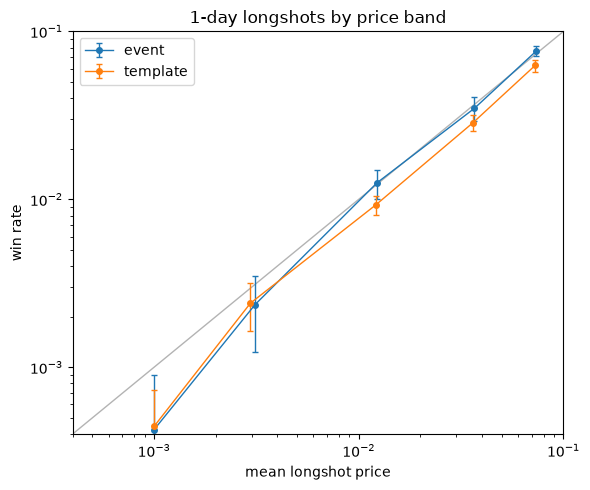

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
lim = [0.0004, 0.1]
ax.plot(lim, lim, color="0.7", lw=1)
for fmt, color in [("event", "tab:blue"), ("template", "tab:orange")]:
    t = bands[bands["format"] == fmt]
    y = t["mean_price"] + t["bias"]
    ax.errorbar(t["mean_price"], y, yerr=[t["bias"] - t["ci_low"], t["ci_high"] - t["bias"]],
                color=color, marker="o", ms=4, lw=1, capsize=2, label=fmt)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("mean longshot price"); ax.set_ylabel("win rate")
ax.set_title("1-day longshots by price band")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "rq2_price_bands.png", dpi=120)

## Reading (exploratory)

- **Not a tick-floor artifact.** The 0.1¢ band carries a small bias in both formats
  (about −0.06¢), as the floor predicts. Above the floor:
  - event longshots are calibrated in every band (each CI covers 0);
  - template longshots are overpriced in every band from 0.6¢ up, by 15–24% of the
    price, and the absolute gap grows with price.
- **By subject, weather and "other" carry it.**
  - Weather is overpriced by about 22% of the price in each band from 0.6¢ up
    (5–10¢: wins 5.9% against a price of 7.5%), and is calibrated below that.
  - "Other" is overpriced from 0.2¢ to 5¢.
  - Crypto is overpriced only in the 0.2–0.5¢ band. Its 0.1¢ cell has no wins, so no
    CI, and its other CIs cover 0.
  - Sports and politics CIs cover 0 in every band; sports, if anything, leans
    underpriced.
- So H2a's confirmatory "yes" describes weather ladders and miscellaneous one-offs.
  It is not a general property of Polymarket longshots.